# LIBERO-Long eval: π0.5 vs X-VLA (Colab, L4)

This notebook evaluates two VLAs on **LIBERO-Long** (`libero_10`, 10 long-horizon tasks), each with the harness its authors used for their published numbers.

| Model | Checkpoint | Size | Harness | Published LIBERO-Long |
|---|---|---|---|---|
| π0.5 | `lerobot/pi05_libero_finetuned` | ~3.3B | LeRobot `lerobot-eval` | 92.4% (OpenPI), 96.0% (LeRobot) |
| X-VLA + LoRA | `2toINF/X-VLA-libero-long-peft` on the X-VLA base model | 0.9B | X-VLA authors' server + `libero_client.py` | 83.2% (authors) |
| X-VLA joint *(optional)* | `lerobot/xvla-libero` | 0.9B | LeRobot `lerobot-eval`, absolute control | — |

**Before you run anything**

1. **Runtime → Change runtime type → L4 GPU.**
2. π0.5 uses the gated PaliGemma tokenizer. Open [google/paligemma-3b-pt-224](https://huggingface.co/google/paligemma-3b-pt-224) while logged in to Hugging Face and accept the license.
3. Add a Hugging Face token as a Colab secret named **`HF_TOKEN`** (key icon in the left sidebar) and switch on *Notebook access*. Read access is enough. If you skip this, the notebook asks you to paste one.
4. Run the cells top to bottom. Each smoke test runs one episode and prints an estimate for the full run. Section 2 asks for permission to use your Google Drive, where results are saved.

**How long it takes.** The default is 50 episodes per task (500 per model), one per LIBERO starting layout. That's the protocol behind OpenPI's 92.4% and the X-VLA client's default. Expect roughly 5.5–9 hours on an L4 for both models. For a quick first pass, set `N_EPISODES_PER_TASK = 10` (100 per model, LeRobot's protocol), but its confidence intervals are about twice as wide (roughly ±5–7 points instead of ±2–3).

**If Colab disconnects.** Results are saved to Google Drive per task (π0.5) and per episode (X-VLA). Re-run the setup cells, then the run cell, and finished work is skipped, even after a full VM reset.

## 1. Settings

In [ ]:
# ===================== Settings =====================
N_EPISODES_PER_TASK = 50        # 50 = all 50 LIBERO starting layouts (500 episodes/model); 10 = quick pass (100)
TASK_IDS = list(range(10))      # LIBERO-Long has 10 tasks, ids 0-9

RUN_PI05 = True
RUN_XVLA_PEFT = True
RUN_XVLA_LEROBOT = False        # optional extra: LeRobot's jointly fine-tuned X-VLA (all 4 suites)

SAVE_TO_DRIVE = True            # write results to Google Drive so they survive a VM reset (False = local disk only)

PI05_CHECKPOINT = "lerobot/pi05_libero_finetuned"
XVLA_LORA = "2toINF/X-VLA-libero-long-peft"
XVLA_BASE = None                # None = read the base model from the adapter's config (fallback: 2toINF/X-VLA-Pt)
XVLA_LEROBOT_CHECKPOINT = "lerobot/xvla-libero"

VIDEOS_PER_TASK = 1             # X-VLA rollout videos kept per task (lerobot-eval keeps up to 10 per task itself)
XVLA_ALSO_SCORE_AT = [520]      # X-VLA runs with its authors' 900-step limit; also score it at these limits from the
                                # same run (a success counts if it finished by then). 520 = π0.5's limit.

# Pinned versions so reruns behave the same
LEROBOT_VERSION = "0.6.1"
XVLA_REPO_COMMIT = "6c4ecfb8be458ae7c0c96094e4b0add4174f4fe2"   # 2toinf/X-VLA main, 2026-10-20
XVLA_PORT = 8777

## 2. Check the runtime and pick an output folder

In [ ]:
import os, sys, json, re, subprocess, shutil, time, math
from pathlib import Path

try:
    gpu = subprocess.run(["nvidia-smi", "--query-gpu=name,memory.total", "--format=csv,noheader"],
                         capture_output=True, text=True).stdout.strip()
except FileNotFoundError:
    gpu = ""
print("GPU:", gpu or "none found")
if not gpu:
    raise RuntimeError("No GPU. Use Runtime → Change runtime type → L4 GPU, then re-run from the top.")
if "L4" not in gpu:
    print("⚠️  This notebook is sized for an L4. Other GPUs with >= 20 GB should also work.")
print("Python:", sys.version.split()[0])
if sys.version_info[:2] not in [(3, 12), (3, 13)]:
    print("⚠️  LeRobot", LEROBOT_VERSION, "needs Python 3.12 or 3.13.")

OUT_ROOT = Path("/content/vla_libero_long_eval")
if SAVE_TO_DRIVE:
    try:
        from google.colab import drive
        drive.mount("/content/drive")
        OUT_ROOT = Path("/content/drive/MyDrive/vla_libero_long_eval")
    except Exception as e:
        print(f"⚠️  Couldn't mount Google Drive ({type(e).__name__}: {e}).")
        print("    Saving to local disk instead; results won't survive a VM reset. Re-run this cell to retry.")
OUT_ROOT.mkdir(parents=True, exist_ok=True)
LOG_DIR = OUT_ROOT / "logs"
LOG_DIR.mkdir(exist_ok=True)
WORK = Path("/content/work")
WORK.mkdir(exist_ok=True)
print("Results and logs go to:", OUT_ROOT)

GPU: Tesla T4, 15360 MiB
⚠️  This notebook is sized for an L4. Other GPUs with >= 20 GB should also work.
Python: 3.13.16
Mounted at /content/drive
Results and logs go to: /content/drive/MyDrive/vla_libero_long_eval


## 3. Hugging Face token

In [ ]:
token = os.environ.get("HF_TOKEN")
if not token:
    try:
        from google.colab import userdata
        token = userdata.get("HF_TOKEN")
    except Exception as e:
        print("Couldn't read the HF_TOKEN Colab secret:", type(e).__name__)
if not token:
    import getpass
    token = getpass.getpass("Paste a Hugging Face token (read access is enough): ").strip()
if token:
    os.environ["HF_TOKEN"] = token
    print("HF token set.")
else:
    print("⚠️  No token. π0.5 will fail on the gated PaliGemma tokenizer.")

HF token set.


## 4. Helpers

In [ ]:
RENDER = {"MUJOCO_GL": "egl", "PYOPENGL_PLATFORM": "egl"}   # switched to osmesa automatically if EGL fails


def base_env(**extra):
    env = os.environ.copy()
    env.update(RENDER)
    env["TOKENIZERS_PARALLELISM"] = "false"
    env.update({k: str(v) for k, v in extra.items()})
    return env


def tail(path, n=60):
    try:
        return "\n".join(Path(path).read_text(errors="replace").splitlines()[-n:])
    except FileNotFoundError:
        return ""


def run_logged(cmd, log_path, env=None, cwd=None, echo=None, check=True):
    # Runs cmd, writes everything to log_path, prints only lines where echo(line) is True.
    log_path = Path(log_path)
    log_path.parent.mkdir(parents=True, exist_ok=True)
    cmd = [str(c) for c in cmd]
    t0 = time.time()
    with open(log_path, "a") as log:
        log.write(f"\n$ {' '.join(cmd)}\n")
        log.flush()
        p = subprocess.Popen(cmd, stdout=subprocess.PIPE, stderr=subprocess.STDOUT, text=True,
                             errors="replace", env=env if env is not None else base_env(),
                             cwd=cwd, bufsize=1)
        for line in p.stdout:
            log.write(line)
            if echo is not None and echo(line):
                print(line.rstrip(), flush=True)
        p.wait()
    if check and p.returncode != 0:
        print(f"--- last lines of {log_path} ---")
        print(tail(log_path))
        raise RuntimeError(f"Command failed (exit {p.returncode}). Full log: {log_path}")
    return p.returncode, time.time() - t0


def run_py(script, *args, env=None, cwd=None, timeout=None):
    # Runs a small Python snippet in a fresh process (so new package versions are picked up).
    r = subprocess.run([sys.executable, "-c", script, *map(str, args)], capture_output=True, text=True,
                       env=env if env is not None else base_env(), cwd=cwd, timeout=timeout)
    return r.returncode, r.stdout, r.stderr


def wilson(k, n, z=1.96):
    if n == 0:
        return float("nan"), float("nan")
    p = k / n
    d = 1 + z * z / n
    c = (p + z * z / (2 * n)) / d
    h = z * math.sqrt(p * (1 - p) / n + z * z / (4 * n * n)) / d
    return 100 * (c - h), 100 * (c + h)


def fmt_rate(k, n):
    if n == 0:
        return "—"
    lo, hi = wilson(k, n)
    return f"{100 * k / n:5.1f}%  ({k}/{n}, 95% CI {lo:.0f}–{hi:.0f})"

print("Helpers ready.")

Helpers ready.


In [ ]:
GL_CHECK = r'''
from mujoco.egl import GLContext
from OpenGL import GL
ctx = GLContext(64, 64); ctx.make_current()
print("GL", GL.glGetString(GL.GL_VENDOR).decode(), "|", GL.glGetString(GL.GL_RENDERER).decode())
ctx.free()
'''
rc, out, err = run_py(GL_CHECK)
print("before:", out.strip() or err[-1500:])

# Register NVIDIA's EGL driver so rendering uses the GPU (same fix as MuJoCo's own Colab tutorials)
icd = Path("/usr/share/glvnd/egl_vendor.d/10_nvidia.json")
if not icd.exists():
    icd.parent.mkdir(parents=True, exist_ok=True)
    icd.write_text('{"file_format_version" : "1.0.0", "ICD" : {"library_path" : "libEGL_nvidia.so.0"}}')
    print("wrote", icd)

rc, out, err = run_py(GL_CHECK)
print("after: ", out.strip() or err[-1500:])

before: Traceback (most recent call last):
  File "<string>", line 2, in <module>
    from mujoco.egl import GLContext
ModuleNotFoundError: No module named 'mujoco'

wrote /usr/share/glvnd/egl_vendor.d/10_nvidia.json
after:  Traceback (most recent call last):
  File "<string>", line 2, in <module>
    from mujoco.egl import GLContext
ModuleNotFoundError: No module named 'mujoco'



## 5. Install LeRobot + LIBERO

Installs `lerobot[pi,xvla,libero]` into Colab's Python. This takes a few minutes. Pip may print dependency warnings about Colab's preinstalled packages, and Colab may offer to restart the session. You don't need to restart, because every evaluation runs in a fresh process. If you do restart, re-run sections 1–4.

In [ ]:
print("Installing system libraries...")
run_logged(["apt-get", "update", "-qq"], LOG_DIR / "apt.log", check=False)
run_logged(["apt-get", "install", "-y", "-qq", "libegl1", "libgl1", "libglfw3", "ffmpeg"], LOG_DIR / "apt.log", check=False)

# LIBERO's dependency chain needs egl_probe + hf_egl_probe, which only ship as source and build with CMake.
# They fail in pip's isolated build env when cmake comes from pip (as on Colab) and on CMake >= 4,
# so build them first without isolation and with CMake's old-policy override.
pip_env = base_env(CMAKE_POLICY_VERSION_MINIMUM="3.5")
install_log = LOG_DIR / "install_lerobot.log"
print("Building egl_probe ...")
run_logged([sys.executable, "-m", "pip", "install", "-q", "cmake>=3.29,<4.2", "setuptools", "wheel"], install_log, env=pip_env)
run_logged([sys.executable, "-m", "pip", "install", "-q", "--no-build-isolation", "egl_probe>=1.0.1", "hf_egl_probe>=1.0.1"],
           install_log, env=pip_env, echo=lambda l: l.startswith("ERROR"))

print(f"Installing lerobot[pi,xvla,libero]=={LEROBOT_VERSION} ...")
pkgs = [f"lerobot[pi,xvla,libero]=={LEROBOT_VERSION}", "json_numpy==2.1.0", "imageio[ffmpeg]", "requests", "pyyaml"]
run_logged([sys.executable, "-m", "pip", "install", "-q", *pkgs], install_log, env=pip_env,
           echo=lambda l: l.startswith("ERROR"))

rc, out, err = run_py(
    "import importlib.metadata as m, torch\n"
    "print('lerobot', m.version('lerobot'), '| torch', torch.__version__, '| transformers', m.version('transformers'),"
    " '| robosuite', m.version('robosuite'), '| mujoco', m.version('mujoco'), '| CUDA', torch.cuda.is_available())"
)
print(out or err)
if rc != 0:
    raise RuntimeError("Install check failed, see output above and logs/install_lerobot.log")

Installing system libraries...
Building egl_probe ...
Installing lerobot[pi,xvla,libero]==0.6.1 ...
lerobot 0.6.1 | torch 2.11.0+cu130 | transformers 5.5.4 | robosuite 1.4.0 | mujoco 3.8.1 | CUDA True



In [ ]:
# Colab's preinstalled diffusers and torchao don't match, and LeRobot imports diffusers at startup
# when it's present. Neither model needs them, so remove both.
run_logged([sys.executable, "-m", "pip", "uninstall", "-y", "diffusers", "torchao"], LOG_DIR / "install_lerobot.log")

rc, out, err = run_py(
    "from lerobot.configs.eval import EvalPipelineConfig\n"
    "import lerobot.policies.pi05.modeling_pi05, lerobot.policies.xvla.modeling_xvla\n"
    "print('LEROBOT_IMPORT_OK')"
)
print(out.strip() or err[-3000:])
if "LEROBOT_IMPORT_OK" not in out:
    raise RuntimeError("LeRobot still fails to import, see the error above")

LEROBOT_IMPORT_OK


## 6. Set up LIBERO and test rendering

Writes LIBERO's config file (LIBERO asks an interactive question on first import otherwise), downloads its scene assets, and renders one frame. If EGL rendering fails, the cell switches to OSMesa, which works but is several times slower.

In [ ]:
SETUP_LIBERO = r'''
import importlib.util, os
from pathlib import Path
import yaml
spec = importlib.util.find_spec("libero")
pkg = Path(spec.origin).parent / "libero"
cfg_dir = Path(os.environ.get("LIBERO_CONFIG_PATH", str(Path.home() / ".libero")))
cfg_dir.mkdir(parents=True, exist_ok=True)
assets = Path.home() / ".cache" / "libero" / "assets"
cfg = {"benchmark_root": str(pkg), "bddl_files": str(pkg / "bddl_files"),
       "init_states": str(pkg / "init_files"), "datasets": str(pkg.parent / "datasets"),
       "assets": str(assets)}
(cfg_dir / "config.yaml").write_text(yaml.safe_dump(cfg))
from huggingface_hub import snapshot_download
snapshot_download(repo_id="lerobot/libero-assets", repo_type="dataset", local_dir=str(assets))
print("LIBERO_CONFIG_OK", cfg_dir / "config.yaml", assets)
'''

RENDER_TEST = r'''
import os, sys, json
import numpy as np
from libero.libero import benchmark, get_libero_path
from libero.libero.envs import OffScreenRenderEnv
suite = benchmark.get_benchmark_dict()["libero_10"]()
json.dump([suite.get_task(i).language for i in range(suite.n_tasks)], open(sys.argv[1], "w"), indent=1)
task = suite.get_task(0)
bddl = os.path.join(get_libero_path("bddl_files"), task.problem_folder, task.bddl_file)
env = OffScreenRenderEnv(bddl_file_name=bddl, camera_heights=128, camera_widths=128)
env.seed(0)
env.reset()
obs, _, _, _ = env.step(np.array([0.0] * 6 + [-1.0]))
img = obs["agentview_image"]
print("RENDER_OK", img.shape, round(float(img.mean()), 1))
env.close()
'''

rc, out, err = run_py(SETUP_LIBERO, timeout=1800)
print(out.strip() or err[-3000:])
if "LIBERO_CONFIG_OK" not in out:
    raise RuntimeError("LIBERO setup failed")

TASKS_FILE = OUT_ROOT / "libero10_tasks.json"
for backend in ["egl", "osmesa"]:
    if backend == "osmesa":
        print("EGL failed; installing OSMesa and retrying (slower rendering)...")
        run_logged(["apt-get", "install", "-y", "-qq", "libosmesa6-dev"], LOG_DIR / "apt.log", check=False)
        run_logged([sys.executable, "-m", "pip", "install", "-q", "PyOpenGL-accelerate"], LOG_DIR / "apt.log", check=False)
    RENDER.update({"MUJOCO_GL": backend, "PYOPENGL_PLATFORM": backend})
    rc, out, err = run_py(RENDER_TEST, TASKS_FILE, timeout=900)
    m = re.search(r"^RENDER_OK (.*) ([\d.]+)$", out, re.M)
    if m:
        print(f"Rendering works with {backend}: frame {m.group(1)}, mean pixel {m.group(2)}")
        if float(m.group(2)) < 1.0:
            print("⚠️  The test frame is almost black. Check logs if success rates come out as 0%.")
        break
    print(f"{backend} render failed:\n", err[-2000:])
else:
    raise RuntimeError("Neither EGL nor OSMesa rendering worked")

TASK_NAMES = json.loads(TASKS_FILE.read_text())
for i, t in enumerate(TASK_NAMES):
    print(f"  task {i}: {t}")

LIBERO_CONFIG_OK /root/.libero/config.yaml /root/.cache/libero/assets
Rendering works with egl: frame (128, 128, 3), mean pixel 68.9
  task 0: put both the alphabet soup and the tomato sauce in the basket
  task 1: put both the cream cheese box and the butter in the basket
  task 2: turn on the stove and put the moka pot on it
  task 3: put the black bowl in the bottom drawer of the cabinet and close it
  task 4: put the white mug on the left plate and put the yellow and white mug on the right plate
  task 5: pick up the book and place it in the back compartment of the caddy
  task 6: put the white mug on the plate and put the chocolate pudding to the right of the plate
  task 7: put both the alphabet soup and the cream cheese box in the basket
  task 8: put both moka pots on the stove
  task 9: put the yellow and white mug in the microwave and close it


## 7. Check model access and pre-download checkpoints

Fails early if the PaliGemma license hasn't been accepted, then downloads the checkpoints you selected.

In [ ]:
DL = r'''
import sys
from huggingface_hub import hf_hub_download, snapshot_download
check_gated = sys.argv[1] == "1"
if check_gated:
    try:
        hf_hub_download("google/paligemma-3b-pt-224", "tokenizer_config.json")
        print("PALIGEMMA_OK")
    except Exception as e:
        print("PALIGEMMA_FAIL", type(e).__name__, str(e)[:300])
        sys.exit(3)
for repo in sys.argv[2:]:
    path = snapshot_download(repo)
    print("DOWNLOADED", repo, path, flush=True)
'''

repos = []
if RUN_PI05:
    repos.append(PI05_CHECKPOINT)
if RUN_XVLA_PEFT:
    repos.append(XVLA_LORA)
if RUN_XVLA_LEROBOT:
    repos.append(XVLA_LEROBOT_CHECKPOINT)

log = LOG_DIR / "downloads.log"
rc, _ = run_logged([sys.executable, "-c", DL, "1" if RUN_PI05 else "0", *repos], log,
                   echo=lambda l: l.startswith(("PALIGEMMA", "DOWNLOADED")), check=False)
if rc == 3:
    raise RuntimeError("Your token can't read google/paligemma-3b-pt-224. Accept the license at "
                       "https://huggingface.co/google/paligemma-3b-pt-224 with the same account, then re-run.")
if rc != 0:
    print(tail(log))
    raise RuntimeError("Download failed, see log above")

PALIGEMMA_OK
DOWNLOADED lerobot/pi05_libero_finetuned /root/.cache/huggingface/hub/models--lerobot--pi05_libero_finetuned/snapshots/7152f13e34c6c115d808aea0e5d08aca74eac14b
DOWNLOADED 2toINF/X-VLA-libero-long-peft /root/.cache/huggingface/hub/models--2toINF--X-VLA-libero-long-peft/snapshots/b6af8e31b153c0c67998ee0bd81bffd45321220d


## 8. π0.5 on LIBERO-Long (LeRobot harness)

Uses LeRobot's published reproduction settings for `pi05_libero_finetuned`: `n_action_steps=10`, one environment at a time, LeRobot's 520-step limit for `libero_10`, and seed 1000. Each task runs in its own `lerobot-eval` process, so a disconnect only loses the task in progress. Results land in `OUT_ROOT/pi05/n{N}/task_{i}/eval_info.json`, along with up to 10 videos per task.

In [ ]:
def read_lerobot_info(path):
    info = json.loads(Path(path).read_text())
    succ = []
    for t in info.get("per_task", []):
        succ += [bool(s) for s in t.get("metrics", {}).get("successes", [])]
    ov = info["overall"]
    if not succ:   # fallback if the per-episode list is missing
        n = int(ov["n_episodes"])
        return round(ov["pc_success"] * n / 100), n, ov.get("eval_ep_s")
    return sum(succ), len(succ), ov.get("eval_ep_s")


def run_lerobot_libero(name, policy_args, env_args=(), n=None, task_ids=None, out_root=None):
    # One lerobot-eval process per LIBERO-Long task; tasks with an eval_info.json are skipped.
    n = n or N_EPISODES_PER_TASK
    task_ids = TASK_IDS if task_ids is None else task_ids
    out_root = Path(out_root) if out_root else OUT_ROOT / name / f"n{n}"
    results, timings = {}, {}
    for tid in task_ids:
        tdir = out_root / f"task_{tid}"
        info_path = tdir / "eval_info.json"
        if info_path.exists():
            k, m, _ = read_lerobot_info(info_path)
            print(f"[{name}] task {tid}: already done, {k}/{m}")
        else:
            shutil.rmtree(tdir, ignore_errors=True)   # clear a half-finished attempt
            cmd = ["lerobot-eval", *policy_args, "--policy.device=cuda",
                   "--env.type=libero", "--env.task=libero_10", f"--env.task_ids=[{tid}]", *env_args,
                   f"--eval.n_episodes={n}", "--eval.batch_size=1", "--env.max_parallel_tasks=1",
                   f"--output_dir={tdir}"]
            print(f"[{name}] task {tid}: running {n} episodes ...", flush=True)
            _, dt = run_logged(cmd, LOG_DIR / f"{name}_n{n}_task{tid}.log", env=base_env())
            k, m, ep_s = read_lerobot_info(info_path)
            timings[tid] = (dt, ep_s)
            print(f"[{name}] task {tid}: {k}/{m} in {dt / 60:.1f} min", flush=True)
        results[tid] = (k, m)
    K = sum(k for k, _ in results.values())
    M = sum(m for _, m in results.values())
    print(f"\n== {name}: {fmt_rate(K, M)}")
    return results, timings


PI05_ARGS = [f"--policy.path={PI05_CHECKPOINT}", "--policy.n_action_steps=10", "--policy.compile_model=false"]

**Smoke test:** one episode of task 0. Run this once to confirm everything works and to get a time estimate.

In [ ]:
if RUN_PI05:
    smoke_dir = OUT_ROOT / "smoke" / "pi05"
    shutil.rmtree(smoke_dir, ignore_errors=True)
    _, tm = run_lerobot_libero("pi05_smoke", PI05_ARGS, n=1, task_ids=[0], out_root=smoke_dir)
    dt, ep_s = tm[0]
    load_s = max(dt - (ep_s or 0), 0)
    total_eps = N_EPISODES_PER_TASK * len(TASK_IDS)
    eta_h = (total_eps * (ep_s or dt) + len(TASK_IDS) * load_s) / 3600
    print(f"One episode took {ep_s or dt:.0f}s (+{load_s:.0f}s startup/model load).")
    print(f"Estimated full π0.5 run ({total_eps} episodes): ~{eta_h:.1f} h (failed episodes run to the step limit, so this varies).")

[pi05_smoke] task 0: running 1 episodes ...
[pi05_smoke] task 0: 1/1 in 3.4 min

== pi05_smoke: 100.0%  (1/1, 95% CI 21–100)
One episode took 29s (+173s startup/model load).
Estimated full π0.5 run (500 episodes): ~4.5 h (failed episodes run to the step limit, so this varies).


In [ ]:
!pkill -f lerobot-eval; sleep 3; nvidia-smi --query-gpu=memory.used --format=csv

^C


**Full run.** Re-run this cell after a disconnect to continue where it stopped.

In [ ]:
from google.colab import runtime

try:
    if RUN_PI05:
        pi05_results, _ = run_lerobot_libero("pi05", PI05_ARGS)
        # save results here (see below)
finally:
    runtime.unregister()

[pi05] task 0: running 50 episodes ...
[pi05] task 0: 48/50 in 23.3 min
[pi05] task 1: running 50 episodes ...
[pi05] task 1: 49/50 in 21.6 min
[pi05] task 2: running 50 episodes ...
[pi05] task 2: 49/50 in 19.9 min
[pi05] task 3: running 50 episodes ...
[pi05] task 3: 49/50 in 19.4 min
[pi05] task 4: running 50 episodes ...
[pi05] task 4: 50/50 in 20.2 min
[pi05] task 5: running 50 episodes ...
[pi05] task 5: 50/50 in 15.6 min
[pi05] task 6: running 50 episodes ...
[pi05] task 6: 47/50 in 20.8 min
[pi05] task 7: running 50 episodes ...
[pi05] task 7: 49/50 in 21.2 min
[pi05] task 8: running 50 episodes ...
[pi05] task 8: 41/50 in 31.3 min
[pi05] task 9: running 50 episodes ...
[pi05] task 9: 46/50 in 22.5 min

== pi05:  95.6%  (478/500, 95% CI 93–97)


AttributeError: module 'google.colab.runtime' has no attribute 'unregister'

## 9. X-VLA + LIBERO-Long LoRA (authors' harness)

This mirrors how the X-VLA authors measured 83.2%:

- **Server:** the authors' `deploy.py` loads the base X-VLA model and applies the `X-VLA-libero-long-peft` LoRA adapter. It runs in its own virtual environment because the authors pin `transformers==4.51.3`, while LeRobot needs 5.x. Torch is shared with Colab's install.
- **Client:** the authors' `libero_client.py` handles absolute end-effector control, 30-action chunks, a 900-step limit, LIBERO init state `ep % 50`, and seed `42 + ep + 100`. A thin wrapper adds resume and per-episode logging, and keeps only `VIDEOS_PER_TASK` videos per task.

Results land in `OUT_ROOT/xvla_peft/progress.jsonl`, one line per episode. Each line records how many steps the episode used, so the results section can also score X-VLA at π0.5's 520-step limit from this same 900-step run. That's a fair stand-in for a separate 520-step run, because the first 520 steps of an episode don't depend on the limit.

In [ ]:
# --- Get the authors' code at a pinned commit ---
XVLA_REPO = WORK / "X-VLA"
setup_log = LOG_DIR / "xvla_setup.log"
if RUN_XVLA_PEFT:
    if not (XVLA_REPO / ".git").exists():
        run_logged(["git", "clone", "-q", "https://github.com/2toinf/X-VLA.git", XVLA_REPO], setup_log)
    run_logged(["git", "-C", XVLA_REPO, "checkout", "-q", XVLA_REPO_COMMIT], setup_log)

    # --- Separate env for the server: authors' pins, Colab's torch ---
    VENV = Path("/content/xvla_env")
    VPY = VENV / "bin" / "python"
    if not VPY.exists():
        run_logged([sys.executable, "-m", "venv", "--without-pip", "--system-site-packages", VENV], setup_log)
    server_pkgs = ["transformers==4.51.3", "peft==0.17.1", "timm==1.0.12", "accelerate==1.2.1",
                   "einops==0.8.1", "uvicorn==0.34.3", "fastapi", "json_numpy==2.1.0", "huggingface_hub<1.0",
                   "opencv-python-headless", "pillow"]
    print("Installing the X-VLA server environment...")
    run_logged([VPY, "-m", "pip", "install", "-q", *server_pkgs], setup_log, echo=lambda l: l.startswith("ERROR"))

    CHECK = ("import torch, transformers, peft, timm, fastapi, uvicorn, json_numpy, cv2; "
             "print(torch.__version__, transformers.__version__, peft.__version__, torch.cuda.is_available())")
    r = subprocess.run([VPY, "-c", CHECK], capture_output=True, text=True, cwd=XVLA_REPO)
    if r.returncode != 0 and "No module named 'torch'" in r.stderr:
        tv = subprocess.run([sys.executable, "-c", "import torch; print(torch.__version__.split('+')[0])"],
                            capture_output=True, text=True).stdout.strip()
        print(f"Torch isn't visible inside the venv; installing torch=={tv} into it...")
        run_logged([VPY, "-m", "pip", "install", "-q", f"torch=={tv}"], setup_log)
        r = subprocess.run([VPY, "-c", CHECK], capture_output=True, text=True, cwd=XVLA_REPO)
    print("server env: torch | transformers | peft | CUDA ->", r.stdout.strip() or r.stderr[-2000:])
    if r.returncode != 0 or " 4.51.3 " not in f" {r.stdout} " or not r.stdout.strip().endswith("True"):
        raise RuntimeError("X-VLA server environment check failed, see logs/xvla_setup.log")

Installing the X-VLA server environment...
ERROR: pip's dependency resolver does not currently take into account all the packages that are installed. This behaviour is the source of the following dependency conflicts.
server env: torch | transformers | peft | CUDA -> 2.11.0+cu130 4.51.3 0.17.1 True


In [ ]:
# --- Find the base model the LoRA adapter was trained on ---
RESOLVE = r'''
import json, sys
from pathlib import Path
from huggingface_hub import snapshot_download
root = Path(snapshot_download(sys.argv[1]))
hits = sorted(root.rglob("adapter_config.json"), key=lambda p: len(p.parts))
if hits:
    cfg = json.loads(hits[0].read_text())
    print("LORA_DIR=" + str(hits[0].parent))
    print("BASE=" + str(cfg.get("base_model_name_or_path")))
    print("LORA=" + json.dumps({k: cfg.get(k) for k in ("peft_type", "r", "lora_alpha", "target_modules", "modules_to_save")}))
else:
    print("LORA_DIR=")
    print("BASE=")
    print("FILES=" + json.dumps(sorted(str(p.relative_to(root)) for p in root.rglob("*") if p.is_file())[:40]))
'''
XVLA_LORA_DIR = None
if RUN_XVLA_PEFT:
    rc, out, err = run_py(RESOLVE, XVLA_LORA)
    if rc != 0:
        raise RuntimeError(err[-2000:])
    lora_dir = re.search(r"^LORA_DIR=(.*)$", out, re.M).group(1).strip()
    raw_base = re.search(r"^BASE=(.*)$", out, re.M).group(1).strip()
    if lora_dir:
        XVLA_LORA_DIR = lora_dir
        print("adapter config:", re.search(r"^LORA=(.*)$", out, re.M).group(1))
        print("adapter's recorded base model:", raw_base)
    else:
        # No adapter_config.json: the repo holds full (merged) weights, so serve it directly.
        print("No adapter_config.json in", XVLA_LORA, "- treating it as a full model. Files:",
              re.search(r"^FILES=(.*)$", out, re.M).group(1))
    if not XVLA_LORA_DIR:
        XVLA_BASE_RESOLVED = XVLA_LORA
    elif XVLA_BASE:
        XVLA_BASE_RESOLVED = XVLA_BASE
    elif re.fullmatch(r"[\w.-]+/[\w.-]+", raw_base) and not raw_base.startswith((".", "/")):
        XVLA_BASE_RESOLVED = raw_base                      # already a Hub id
    elif Path(raw_base).name in ("X-VLA-Pt", "X-VLA-Libero"):
        XVLA_BASE_RESOLVED = "2toINF/" + Path(raw_base).name   # a local path on the authors' machine
    else:
        XVLA_BASE_RESOLVED = "2toINF/X-VLA-Pt"
    print("Using base model:", XVLA_BASE_RESOLVED)
    run_logged([sys.executable, "-c", DL, "0", XVLA_BASE_RESOLVED], LOG_DIR / "downloads.log",
               echo=lambda l: l.startswith("DOWNLOADED"))

adapter config: {"peft_type": "LORA", "r": 8, "lora_alpha": 16, "target_modules": ["qkv", "fc2", "fc1", "out_proj", "attn.proj", "q_proj", "k_proj", "v_proj", "vlm_proj", "fn.proj", "aux_visual_proj"], "modules_to_save": ["transformer.soft_prompt_hub", "transformer.action_encoder", "transformer.action_decoder"]}
adapter's recorded base model: 2toINF/X-VLA-Pt
Using base model: 2toINF/X-VLA-Pt
DOWNLOADED 2toINF/X-VLA-Pt /root/.cache/huggingface/hub/models--2toINF--X-VLA-Pt/snapshots/c1c4a64a7e03ac5b95c468bf1578f3d03651b53b


The wrapper around the authors' client. It's written to `/content/work/xvla_libero_runner.py`.

In [ ]:
%%writefile /content/work/xvla_libero_runner.py
# Resumable LIBERO runner around the X-VLA authors' evaluation/libero/libero_client.py.
# Env setup, action conversion and success checks are the authors' code; this adds resume + logging.
import argparse
import json
import sys
import time
from pathlib import Path

ap = argparse.ArgumentParser()
ap.add_argument("--xvla_repo", required=True)
ap.add_argument("--host", default="127.0.0.1")
ap.add_argument("--port", type=int, default=8777)
ap.add_argument("--suite", default="libero_10")
ap.add_argument("--task_ids", type=int, nargs="*", default=None)
ap.add_argument("--episodes", type=int, default=10)
ap.add_argument("--init_seed", type=int, default=42)
ap.add_argument("--out", required=True)
ap.add_argument("--videos_per_task", type=int, default=1)
ap.add_argument("--also_score_at", type=int, nargs="*", default=[520],
                help="extra step limits to score from the same run (a success counts if it finished by then)")
args = ap.parse_args()

sys.path.insert(0, str(Path(args.xvla_repo) / "evaluation" / "libero"))
import libero_client as lc  # noqa: E402  (authors' client)


class StepCountingClient(lc.ClientModel):
    # The authors' rollout calls policy.step() exactly once per simulator step (the 10 settle steps
    # call env.step directly and aren't counted), so this counts the steps an episode actually used.
    def reset(self):
        super().reset()
        self.n_steps = 0

    def step(self, obs, goal):
        self.n_steps += 1
        return super().step(obs, goal)

out = Path(args.out)
out.mkdir(parents=True, exist_ok=True)
progress_path = out / "progress.jsonl"
done = {}
if progress_path.exists():
    for line in progress_path.read_text().splitlines():
        if line.strip():
            r = json.loads(line)
            done[(r["task_id"], r["episode"])] = r

horizon = lc.LIBERO_DATASETS_HORIZON[args.suite]   # authors' step limit: 900 for libero_10
evaluator = lc.LIBEROEval(
    task_suite_name=args.suite,
    eval_horizon=horizon,
    act_type="abs",
    num_episodes=args.episodes,
    init_seed=args.init_seed,
)
evaluator._make_dir(out / "rollouts")
suite = evaluator.task_suite_list[0]
task_ids = args.task_ids if args.task_ids else list(range(len(suite.tasks)))

current = {"episode": 0}
_save_video = evaluator._save_video


def save_some_videos(save_path, images, fps=30):
    if current["episode"] < args.videos_per_task:
        _save_video(save_path, images, fps=fps)


evaluator._save_video = save_some_videos

client = StepCountingClient(args.host, args.port)
wanted = [(t, e) for t in task_ids for e in range(args.episodes)]
print(f"[runner] {sum(k in done for k in wanted)}/{len(wanted)} episodes already done", flush=True)

for tid in task_ids:
    lang = suite.get_task(tid).language
    for ep in range(args.episodes):
        if (tid, ep) in done:
            continue
        current["episode"] = ep
        client.reset()
        t0 = time.time()
        success = evaluator._rollout(suite, client, tid, ep)
        rec = {"task_id": tid, "episode": ep, "success": bool(success), "steps": client.n_steps,
               "step_limit": horizon, "task": lang, "seconds": round(time.time() - t0, 1)}
        with progress_path.open("a") as f:
            f.write(json.dumps(rec) + "\n")
        done[(tid, ep)] = rec
        fin = [done[k] for k in wanted if k in done]
        print(f"[runner] task {tid} ep {ep}: {'SUCCESS' if success else 'fail'} after {rec['steps']} steps, "
              f"{rec['seconds']:.0f}s | {sum(r['success'] for r in fin)}/{len(fin)} successful so far "
              f"({len(fin)}/{len(wanted)} done)", flush=True)


def score(rs, limit=None):
    # Successes within `limit` steps; records from older runs without a step count can't be scored at a lower limit.
    if limit is None:
        return sum(r["success"] for r in rs), len(rs)
    rs = [r for r in rs if "steps" in r]
    return sum(r["success"] and r["steps"] <= limit for r in rs), len(rs)


fin = [done[k] for k in wanted if k in done]
k, n = score(fin)
summary = {"suite": args.suite, "episodes_per_task": args.episodes, "step_limit": horizon,
           "n_success": k, "n_episodes": n, "also_scored_at": {}, "per_task": {}}
for lim in args.also_score_at:
    kl, nl = score(fin, lim)
    summary["also_scored_at"][str(lim)] = {"n_success": kl, "n_episodes": nl}
for tid in task_ids:
    rs = [done[(tid, e)] for e in range(args.episodes) if (tid, e) in done]
    kt, nt = score(rs)
    steps_ok = sorted(r["steps"] for r in rs if r["success"] and "steps" in r)
    summary["per_task"][str(tid)] = {"n_success": kt, "n_episodes": nt, "success_steps": steps_ok,
                                     **{f"n_success_within_{lim}": score(rs, lim)[0] for lim in args.also_score_at}}
(out / f"summary_n{args.episodes}.json").write_text(json.dumps(summary, indent=2))
extra = ", ".join(f"{v['n_success']}/{v['n_episodes']} within {lim} steps" for lim, v in summary["also_scored_at"].items())
print(f"[runner] DONE {k}/{n} successful within {horizon} steps" + (f" ({extra})" if extra else ""), flush=True)

Writing /content/work/xvla_libero_runner.py


Start the X-VLA server. The first start loads about 3.6 GB of weights, and the cell sends one test request before it reports ready.

In [ ]:
import urllib.request

SERVER_LOG = LOG_DIR / "xvla_server.log"
server_proc = globals().get("server_proc")

TEST_REQUEST = r'''
import sys, json_numpy, numpy as np, requests
img = np.zeros((256, 256, 3), dtype=np.uint8)
payload = {"proprio": json_numpy.dumps(np.zeros(20)), "language_instruction": "put both moka pots on the stove",
           "image0": json_numpy.dumps(img), "image1": json_numpy.dumps(img), "domain_id": 3, "steps": 10}
r = requests.post(f"http://127.0.0.1:{sys.argv[1]}/act", json=payload, timeout=300)
r.raise_for_status()
print("ACTION_SHAPE", np.array(r.json()["action"]).shape)
'''


def start_xvla_server(timeout_s=1200):
    global server_proc
    if server_proc is not None and server_proc.poll() is None:
        print("X-VLA server is already running.")
        return
    info_dir = WORK / "xvla_server_info"            # deploy.py refuses to start if info.json exists
    shutil.rmtree(info_dir, ignore_errors=True)
    start_mark = f"=== server start {time.strftime('%Y-%m-%d %H:%M:%S')} ==="
    with open(SERVER_LOG, "a") as f:
        f.write(f"\n{start_mark}\n")
    cmd = [str(VPY), "-m", "deploy", "--model_path", XVLA_BASE_RESOLVED,
           "--host", "127.0.0.1", "--port", str(XVLA_PORT), "--output_dir", str(info_dir), "--disable_slurm"]
    if XVLA_LORA_DIR:
        cmd += ["--LoRA_path", XVLA_LORA_DIR]
    server_proc = subprocess.Popen(cmd, cwd=XVLA_REPO, env=base_env(PYTHONUNBUFFERED=1),
                                   stdout=open(SERVER_LOG, "a"), stderr=subprocess.STDOUT)
    t0 = time.time()
    while True:
        if server_proc.poll() is not None:
            print(tail(SERVER_LOG, 80))
            raise RuntimeError("The X-VLA server exited, see the log above")
        try:
            urllib.request.urlopen(f"http://127.0.0.1:{XVLA_PORT}/docs", timeout=3)
            break
        except Exception:
            if time.time() - t0 > timeout_s:
                print(tail(SERVER_LOG, 80))
                raise TimeoutError("The X-VLA server didn't come up in time")
            time.sleep(5)
    this_run = SERVER_LOG.read_text(errors="replace").split(start_mark)[-1]
    checks = [("XVLAProcessor loaded successfully", "processor")]
    if XVLA_LORA_DIR:
        checks.append(("LoRA weights applied successfully", "LoRA adapter"))
    for needle, what in checks:
        if needle not in this_run:
            print(tail(SERVER_LOG, 80))
            raise RuntimeError(f"Server is up but the {what} didn't load, see the log above")
    rc, out, err = run_py(TEST_REQUEST, XVLA_PORT, timeout=600)
    if "ACTION_SHAPE" not in out:
        print(err[-2000:])
        print(tail(SERVER_LOG, 40))
        raise RuntimeError("Test request to the X-VLA server failed")
    print(f"X-VLA server ready in {time.time() - t0:.0f}s, test action chunk shape {out.split('ACTION_SHAPE')[-1].strip()}")


def stop_xvla_server():
    global server_proc
    if server_proc is not None and server_proc.poll() is None:
        server_proc.terminate()
        try:
            server_proc.wait(30)
        except subprocess.TimeoutExpired:
            server_proc.kill()
        print("X-VLA server stopped.")
    server_proc = None


def run_xvla(n, task_ids, out_dir):
    cmd = [sys.executable, WORK / "xvla_libero_runner.py", "--xvla_repo", XVLA_REPO, "--port", XVLA_PORT,
           "--suite", "libero_10", "--episodes", n, "--task_ids", *task_ids, "--init_seed", 42,
           "--out", out_dir, "--videos_per_task", VIDEOS_PER_TASK, "--also_score_at", *XVLA_ALSO_SCORE_AT]
    run_logged(cmd, LOG_DIR / "xvla_peft_runs.log", env=base_env(TQDM_DISABLE=1, PYTHONUNBUFFERED=1),
               cwd=WORK, echo=lambda l: l.startswith("[runner]"))


if RUN_XVLA_PEFT:
    start_xvla_server()

X-VLA server ready in 35s, test action chunk shape (30, 20)


In [ ]:
# ---- Model response latency: π0.5 (direct model call) and X-VLA (HTTP request to its server) ----
import statistics, urllib.request

N_CALLS = 20   # timed calls per model, after 3 untimed warm-up calls

PI05_LATENCY = r'''
import sys, time, torch
from pathlib import Path
from lerobot.configs.policies import PreTrainedConfig
from lerobot.envs.configs import LiberoEnv
from lerobot.envs import make_env, make_env_pre_post_processors, preprocess_observation
from lerobot.envs.utils import NEW_ROLLOUT_OPTION
from lerobot.policies import make_policy, make_pre_post_processors

ckpt, n = sys.argv[1], int(sys.argv[2])
torch.backends.cudnn.benchmark = True
torch.backends.cuda.matmul.allow_tf32 = True          # same as lerobot-eval
cfg = PreTrainedConfig.from_pretrained(ckpt)
cfg.pretrained_path = Path(ckpt)                       # load the real weights
cfg.device, cfg.compile_model, cfg.n_action_steps = "cuda", False, 10
env_cfg = LiberoEnv(task="libero_10", task_ids=[0])
env = make_env(env_cfg, n_envs=1)["libero_10"][0]
policy = make_policy(cfg=cfg, env_cfg=env_cfg); policy.eval()
pre, post = make_pre_post_processors(policy_cfg=cfg, pretrained_path=ckpt,
                                     preprocessor_overrides={"device_processor": {"device": "cuda"}})
env_pre, _ = make_env_pre_post_processors(env_cfg=env_cfg, policy_cfg=cfg)
obs, _ = env.reset(seed=[0], options={NEW_ROLLOUT_OPTION: True})
o = preprocess_observation(obs)
o["task"] = list(env.call("task_description"))
batch = pre(env_pre(o))                                # same pipeline as lerobot-eval
ts = []
with torch.inference_mode():
    for i in range(n + 3):
        torch.cuda.synchronize(); t = time.perf_counter()
        chunk = policy.predict_action_chunk(batch)
        torch.cuda.synchronize(); dt = time.perf_counter() - t
        if i >= 3:
            ts.append(dt)
print("CHUNK_SHAPE", tuple(chunk.shape))
print("GPU_MEM_GB", round(torch.cuda.max_memory_allocated() / 1e9, 1))
print("LATENCY_S", " ".join(f"{x:.4f}" for x in ts))
env.close()
'''

XVLA_LATENCY = r'''
import sys, time, json_numpy, numpy as np, requests
port, n = int(sys.argv[1]), int(sys.argv[2])
rng = np.random.default_rng(0)
img0 = rng.integers(0, 256, (256, 256, 3), dtype=np.uint8)
img1 = rng.integers(0, 256, (256, 256, 3), dtype=np.uint8)
ts = []
for i in range(n + 3):
    t = time.perf_counter()
    payload = {"proprio": json_numpy.dumps(np.zeros(20)), "language_instruction": "put both moka pots on the stove",
               "image0": json_numpy.dumps(img0), "image1": json_numpy.dumps(img1), "domain_id": 3, "steps": 10}
    r = requests.post(f"http://127.0.0.1:{port}/act", json=payload, timeout=300)
    r.raise_for_status()
    action = np.array(r.json()["action"])
    dt = time.perf_counter() - t
    if i >= 3:
        ts.append(dt)
print("CHUNK_SHAPE", action.shape)
print("LATENCY_S", " ".join(f"{x:.4f}" for x in ts))
'''


def summarize(name, out, err, actions_run_per_call):
    m = re.search(r"^LATENCY_S (.*)$", out, re.M)
    if not m:
        print(f"{name}: failed\n{(err or out)[-2500:]}")
        return
    ms = sorted(1000 * float(x) for x in m.group(1).split())
    p90 = ms[min(len(ms) - 1, int(0.9 * (len(ms) - 1) + 0.5))]
    shape = re.search(r"^CHUNK_SHAPE (.*)$", out, re.M).group(1)
    mem = re.search(r"^GPU_MEM_GB (.*)$", out, re.M)
    med = statistics.median(ms)
    print(f"{name:<8} median {med:5.0f} ms | mean {statistics.mean(ms):5.0f} | p90 {p90:5.0f} | min {ms[0]:5.0f} | "
          f"chunk {shape}" + (f" | GPU {mem.group(1)} GB" if mem else ""))
    print(f"{'':<8} runs {actions_run_per_call} actions per call -> {med / actions_run_per_call:.0f} ms of model time per robot step")


print("Timing π0.5 (loads the model first, ~1-3 min)...")
rc, out, err = run_py(PI05_LATENCY, PI05_CHECKPOINT, N_CALLS, timeout=1800)
summarize("π0.5", out, err, 10)

try:
    urllib.request.urlopen(f"http://127.0.0.1:{XVLA_PORT}/docs", timeout=3)
except Exception:
    print("\nX-VLA server isn't running; starting it...")
    start_xvla_server()
rc, out, err = run_py(XVLA_LATENCY, XVLA_PORT, N_CALLS, timeout=1800)
summarize("X-VLA", out, err, 30)

Timing π0.5 (loads the model first, ~1-3 min)...
π0.5     median   435 ms | mean   436 | p90   439 | min   431 | chunk (1, 50, 7) | GPU 9.5 GB
         runs 10 actions per call -> 44 ms of model time per robot step
X-VLA    median   420 ms | mean   419 | p90   422 | min   414 | chunk (30, 20)
         runs 30 actions per call -> 14 ms of model time per robot step


In [ ]:
#PEAK MEMORY FOR XVLA

!nvidia-smi --query-compute-apps=pid,process_name,used_memory --format=csv

pid, process_name, used_gpu_memory [MiB]
7112, /content/xvla_env/bin/python, 4038 MiB


**Smoke test:** one episode of task 0, plus a time estimate.

In [ ]:
if RUN_XVLA_PEFT:
    smoke_dir = OUT_ROOT / "smoke" / "xvla_peft"
    shutil.rmtree(smoke_dir, ignore_errors=True)
    run_xvla(1, [0], smoke_dir)
    rec = json.loads((smoke_dir / "progress.jsonl").read_text().splitlines()[-1])
    total_eps = N_EPISODES_PER_TASK * len(TASK_IDS)
    print(f"One episode took {rec['seconds']:.0f}s. Estimated full X-VLA run ({total_eps} episodes): "
          f"~{rec['seconds'] * total_eps / 3600:.1f} h (failed episodes run to the step limit, so this varies).")

[runner] 0/1 episodes already done
[runner] task 0 ep 0: SUCCESS after 249 steps, 16s | 1/1 successful so far (1/1 done)
[runner] DONE 1/1 successful within 900 steps (1/1 within 520 steps)
One episode took 16s. Estimated full X-VLA run (500 episodes): ~2.2 h (failed episodes run to the step limit, so this varies).


**Full run.** Re-run this cell after a disconnect; if the server died with the session, it restarts automatically.

In [ ]:
if RUN_XVLA_PEFT:
    start_xvla_server()
    run_xvla(N_EPISODES_PER_TASK, TASK_IDS, OUT_ROOT / "xvla_peft")

X-VLA server is already running.
[runner] 0/500 episodes already done
[runner] task 0 ep 0: SUCCESS after 250 steps, 16s | 1/1 successful so far (1/500 done)
[runner] task 0 ep 1: SUCCESS after 258 steps, 14s | 2/2 successful so far (2/500 done)
[runner] task 0 ep 2: fail after 900 steps, 41s | 2/3 successful so far (3/500 done)
[runner] task 0 ep 3: SUCCESS after 418 steps, 21s | 3/4 successful so far (4/500 done)
[runner] task 0 ep 4: SUCCESS after 387 steps, 19s | 4/5 successful so far (5/500 done)
[runner] task 0 ep 5: fail after 900 steps, 41s | 4/6 successful so far (6/500 done)
[runner] task 0 ep 6: SUCCESS after 812 steps, 37s | 5/7 successful so far (7/500 done)
[runner] task 0 ep 7: SUCCESS after 290 steps, 15s | 6/8 successful so far (8/500 done)
[runner] task 0 ep 8: SUCCESS after 257 steps, 14s | 7/9 successful so far (9/500 done)
[runner] task 0 ep 9: SUCCESS after 239 steps, 13s | 8/10 successful so far (10/500 done)
[runner] task 0 ep 10: SUCCESS after 264 steps, 14s | 

In [ ]:
# Free the GPU when you're done with X-VLA
stop_xvla_server()

X-VLA server stopped.


## 10. *(Optional)* LeRobot's joint X-VLA checkpoint

`lerobot/xvla-libero` is X-VLA fine-tuned on all four LIBERO suites together. It isn't the checkpoint behind the 83.2% figure, and it's expected to score higher. It's here as a cross-check through a second harness. X-VLA predicts absolute poses, so `--env.control_mode=absolute` is required, otherwise it scores 0%. The other settings follow LeRobot's X-VLA docs.

In [ ]:
XVLA_LEROBOT_ARGS = [f"--policy.path={XVLA_LEROBOT_CHECKPOINT}"]
XVLA_LEROBOT_ENV = ["--env.control_mode=absolute", "--env.episode_length=800"]
if RUN_XVLA_LEROBOT:
    run_lerobot_libero("xvla_lerobot", XVLA_LEROBOT_ARGS, XVLA_LEROBOT_ENV)

## 11. Results

In [ ]:
N = N_EPISODES_PER_TASK
names = TASK_NAMES if "TASK_NAMES" in globals() else [f"task {i}" for i in range(10)]


def collect_lerobot(name):
    res = {}
    for tid in TASK_IDS:
        p = OUT_ROOT / name / f"n{N}" / f"task_{tid}" / "eval_info.json"
        if p.exists():
            k, m, _ = read_lerobot_info(p)
            res[tid] = (k, m)
    return res


def xvla_records():
    p = OUT_ROOT / "xvla_peft" / "progress.jsonl"
    recs = []
    if p.exists():
        for line in p.read_text().splitlines():
            if line.strip():
                r = json.loads(line)
                if r["task_id"] in TASK_IDS and r["episode"] < N:
                    recs.append(r)
    return recs


def collect_xvla_peft(limit=None):
    # limit=None scores at the run's own limit (900). A lower limit counts a success only if it
    # finished within that many steps; episodes logged without a step count are left out.
    res = {}
    for r in xvla_records():
        if limit is not None and "steps" not in r:
            continue
        ok = r["success"] and (limit is None or r["steps"] <= limit)
        k, m = res.get(r["task_id"], (0, 0))
        res[r["task_id"]] = (k + int(ok), m + 1)
    return res


models = {}
if RUN_PI05:
    models["π0.5 @520"] = (collect_lerobot("pi05"), "92.4 (OpenPI) / 96.0 (LeRobot), both at 520 steps")
if RUN_XVLA_PEFT:
    models["X-VLA + LoRA @900"] = (collect_xvla_peft(), "83.2 (authors) at 900 steps")
    for lim in XVLA_ALSO_SCORE_AT:
        models[f"X-VLA + LoRA @{lim}"] = (collect_xvla_peft(lim), f"— (same run, scored at {lim} steps)")
if RUN_XVLA_LEROBOT:
    models["X-VLA joint @800"] = (collect_lerobot("xvla_lerobot"), "—")

cols = list(models)
print(f"LIBERO-Long, {N} episodes per task\n")
print(f"{'task':<4} {'':<62}" + "".join(f"{c:>24}" for c in cols))
for tid in TASK_IDS:
    row = f"{tid:<4} {names[tid][:60]:<62}"
    for c in cols:
        k, m = models[c][0].get(tid, (0, 0))
        row += f"{(f'{k}/{m}' if m else '—'):>24}"
    print(row)

summary = {"episodes_per_task": N, "task_ids": TASK_IDS, "models": {}}
print()
for c in cols:
    res, ref = models[c]
    K = sum(k for k, _ in res.values())
    M = sum(m for _, m in res.values())
    missing = N * len(TASK_IDS) - M
    note = f"   ⚠️ {missing} episodes not run yet" if missing else ""
    print(f"{c:<24} {fmt_rate(K, M):<40} published: {ref}{note}")
    summary["models"][c] = {"n_success": K, "n_episodes": M,
                            "success_rate": (100 * K / M) if M else None,
                            "ci95": list(wilson(K, M)) if M else None, "published": ref,
                            "per_task": {str(t): {"n_success": k, "n_episodes": m} for t, (k, m) in res.items()}}

(OUT_ROOT / f"summary_n{N}.json").write_text(json.dumps(summary, indent=2, ensure_ascii=False))
with open(OUT_ROOT / f"summary_n{N}.csv", "w") as f:
    f.write("task_id,task," + ",".join(f"{c} successes,{c} episodes" for c in cols) + "\n")
    for tid in TASK_IDS:
        cells_ = []
        for c in cols:
            k, m = models[c][0].get(tid, (0, 0))
            cells_ += [str(k), str(m)]
        f.write(f"{tid},\"{names[tid]}\"," + ",".join(cells_) + "\n")
print(f"\nSaved {OUT_ROOT / f'summary_n{N}.json'} and .csv")

LIBERO-Long, 50 episodes per task

task                                                                              π0.5 @520       X-VLA + LoRA @900       X-VLA + LoRA @520
0    put both the alphabet soup and the tomato sauce in the baske                     48/50                   37/50                   36/50
1    put both the cream cheese box and the butter in the basket                       49/50                   37/50                   36/50
2    turn on the stove and put the moka pot on it                                     49/50                   44/50                   44/50
3    put the black bowl in the bottom drawer of the cabinet and c                     49/50                   47/50                   46/50
4    put the white mug on the left plate and put the yellow and w                     50/50                   34/50                   34/50
5    pick up the book and place it in the back compartment of the                     50/50                   43/50          

**How many steps X-VLA's successful episodes actually used.** Failed episodes always run the full 900 steps.

task                                                       wins  median   max   >520
0    put both the alphabet soup and the tomato sauce in   37/50     265   812      1
1    put both the cream cheese box and the butter in th   37/50     250   777      1
2    turn on the stove and put the moka pot on it         44/50     234   267      0
3    put the black bowl in the bottom drawer of the cab   47/50     228   783      1
4    put the white mug on the left plate and put the ye   34/50     219   414      0
5    pick up the book and place it in the back compartm   43/50     175   726      1
6    put the white mug on the plate and put the chocola   38/50     228   837      3
7    put both the alphabet soup and the cream cheese bo   40/50     252   303      0
8    put both moka pots on the stove                      43/50     397   490      0
9    put the yellow and white mug in the microwave and    49/50     261   476      0

412 successes: median 247 steps, 90th percentile 387, longest 83

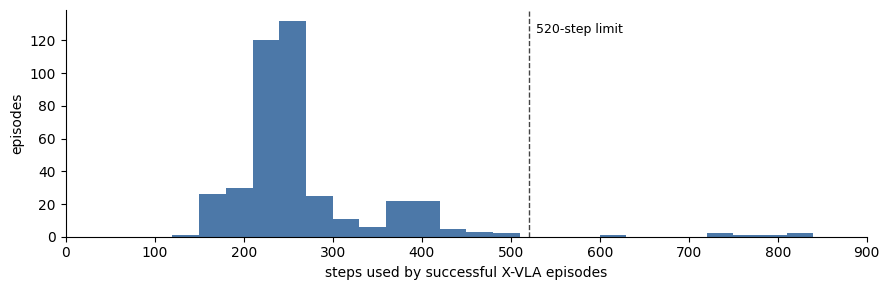

In [ ]:
recs = [r for r in xvla_records() if "steps" in r] if RUN_XVLA_PEFT else []
wins = [r for r in recs if r["success"]]
if not recs:
    print("No X-VLA episodes with step counts yet.")
else:
    def pct(xs, q):
        xs = sorted(xs)
        return xs[min(len(xs) - 1, int(q * (len(xs) - 1) + 0.5))]

    cut = min(XVLA_ALSO_SCORE_AT) if XVLA_ALSO_SCORE_AT else 520
    print(f"{'task':<4} {'':<52}{'wins':>6}{'median':>8}{'max':>6}{f'>{cut}':>7}")
    for tid in TASK_IDS:
        st = [r["steps"] for r in wins if r["task_id"] == tid]
        n_t = sum(1 for r in recs if r["task_id"] == tid)
        if st:
            print(f"{tid:<4} {names[tid][:50]:<52}{f'{len(st)}/{n_t}':>6}{pct(st, 0.5):>8}{max(st):>6}"
                  f"{sum(s > cut for s in st):>7}")
        else:
            print(f"{tid:<4} {names[tid][:50]:<52}{f'0/{n_t}':>6}{'—':>8}{'—':>6}{'—':>7}")
    if wins:
        st = [r["steps"] for r in wins]
        late = sum(s > cut for s in st)
        print(f"\n{len(wins)} successes: median {pct(st, 0.5)} steps, 90th percentile {pct(st, 0.9)}, longest {max(st)}.")
        print(f"{late} of them ({100 * late / len(wins):.0f}%) needed more than {cut} steps, "
              f"so they'd count as failures under π0.5's limit.")
        try:
            import matplotlib.pyplot as plt
            fig, ax = plt.subplots(figsize=(9, 3))
            ax.hist(st, bins=range(0, 901, 30), color="#4C78A8")
            ax.axvline(cut, color="#444", linestyle="--", linewidth=1)
            ax.text(cut + 8, ax.get_ylim()[1] * 0.9, f"{cut}-step limit", fontsize=9)
            ax.set_xlabel("steps used by successful X-VLA episodes")
            ax.set_ylabel("episodes")
            ax.set_xlim(0, 900)
            ax.spines[["top", "right"]].set_visible(False)
            plt.tight_layout()
            plt.show()
        except Exception as e:
            print("Skipping histogram:", e)

In [ ]:
# Per-task chart (optional)
try:
    import matplotlib.pyplot as plt
    fig, ax = plt.subplots(figsize=(11, 4))
    width = 0.8 / max(len(cols), 1)
    for j, c in enumerate(cols):
        res = models[c][0]
        ys = [100 * res[t][0] / res[t][1] if t in res and res[t][1] else 0 for t in TASK_IDS]
        ax.bar([i + j * width for i in range(len(TASK_IDS))], ys, width, label=c)
    ax.set_xticks([i + width * (len(cols) - 1) / 2 for i in range(len(TASK_IDS))])
    ax.set_xticklabels([str(t) for t in TASK_IDS])
    ax.set_xlabel("LIBERO-Long task id")
    ax.set_ylabel("success rate (%)")
    ax.set_ylim(0, 100)
    ax.legend(frameon=False)
    ax.spines[["top", "right"]].set_visible(False)
    plt.tight_layout()
    plt.show()
except Exception as e:
    print("Skipping chart:", e)

## Troubleshooting

- **Where are the logs?** In `OUT_ROOT/logs/`. There's one log per π0.5 task, `xvla_server.log` for the X-VLA server, and `xvla_peft_runs.log` for the X-VLA client. Rollout videos are saved under `OUT_ROOT/pi05/n{N}/task_*/videos/` and `OUT_ROOT/xvla_peft/rollouts/`.
- **401 or "gated" errors for π0.5.** Accept the license on [google/paligemma-3b-pt-224](https://huggingface.co/google/paligemma-3b-pt-224) with the same account as your token, then re-run section 7.
- **EGL or OpenGL errors, or every episode fails instantly.** Re-run section 6. It switches to OSMesa automatically if EGL can't render.
- **The X-VLA server exits on start.** Look at `logs/xvla_server.log`. If the adapter turns out to need a different base model, set `XVLA_BASE` in section 1, for example `"2toINF/X-VLA-Libero"`.
- **After a disconnect.** If the notebook's variables are gone but the VM survived, re-run sections 1–4 and then the full-run cell you were on. If the VM was reset, re-run everything. With `SAVE_TO_DRIVE = True`, finished episodes are still skipped.
- **Scores below the published numbers.** Look at the confidence interval first. At 500 episodes a gap of 2–3 points is within noise, and at 100 episodes about 5–7 points. The X-VLA authors also note a drop of about 1% after converting their models to the HF format.